In [ ]:
pip install pandas numpy matplotlib seaborn scikit-learn ucimlrepo

In [ ]:
# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Base de dados
from ucimlrepo import fetch_ucirepo

# Validação cruzada e busca de hiperparâmetros
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate

# Pré-processamento
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer

# Classificadores
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Métricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, make_scorer)

# Configurações gerais
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

SEED = 42
np.random.seed(SEED)

In [ ]:
import sklearn, matplotlib
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)

pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2


In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_shoppers_purchasing_intention_dataset = fetch_ucirepo(id=468)

# data (as pandas dataframes)
X = online_shoppers_purchasing_intention_dataset.data.features
y = online_shoppers_purchasing_intention_dataset.data.targets

# metadata
print(online_shoppers_purchasing_intention_dataset.metadata)

# variable information
print(online_shoppers_purchasing_intention_dataset.variables)


{'uci_id': 468, 'name': 'Online Shoppers Purchasing Intention Dataset', 'repository_url': 'https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/468/data.csv', 'abstract': 'Of the 12,330 sessions in the dataset,\n84.5% (10,422) were negative class samples that did not\nend with shopping, and the rest (1908) were positive class\nsamples ending with shopping.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 12330, 'num_features': 17, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Revenue'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2018, 'last_updated': 'Thu Jan 11 2024', 'dataset_doi': '10.24432/C5F88Q', 'creators': ['C. Sakar', 'Yomi Kastro'], 'intro_paper': {'ID': 367, 'type': 'NATIVE', 'title': 'Real-time prediction of online shoppers’ pur

In [ ]:
# y vem como DataFrame de uma coluna; o scikit-learn espera uma Series (1D)
y = y["Revenue"].astype(int)          # True/False -> 1/0

# Weekend também vem como booleano
X = X.copy()
X["Weekend"] = X["Weekend"].astype(int)

# DataFrame completo para a análise exploratória
df = pd.concat([X, y], axis=1)

print(X.shape, y.shape)
df.head()

(12330, 17) (12330,)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


(12330, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficTyp

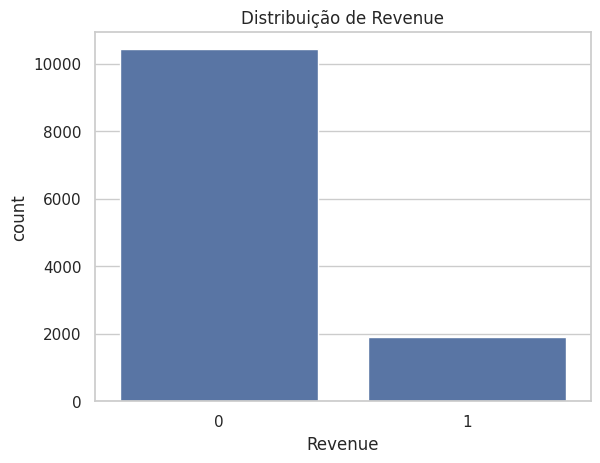

In [ ]:
print(df.shape)
df.info()

print(df.isna().sum().sum(), "valores ausentes")
print(df.duplicated().sum(), "linhas duplicadas")

print(y.value_counts(normalize=True).round(3))
sns.countplot(x=y); plt.title("Distribuição de Revenue"); plt.show()

In [ ]:
# Conferir o que a tabela da UCI declara
print(df[["Administrative_Duration", "PageValues", "SpecialDay"]].head())
print(df["SpecialDay"].unique())

for col in ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]:
    print(col, "→", df[col].nunique(), "categorias:", sorted(df[col].unique()))

print((df.select_dtypes("number") < 0).sum())  # valores negativos?

   Administrative_Duration  PageValues  SpecialDay
0                      0.0         0.0         0.0
1                      0.0         0.0         0.0
2                      0.0         0.0         0.0
3                      0.0         0.0         0.0
4                      0.0         0.0         0.0
[0.  0.4 0.8 1.  0.2 0.6]
Month → 10 categorias: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
VisitorType → 3 categorias: ['New_Visitor', 'Other', 'Returning_Visitor']
OperatingSystems → 8 categorias: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Browser → 13 categorias: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]
Region → 9 categorias: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
TrafficType → 20 cate

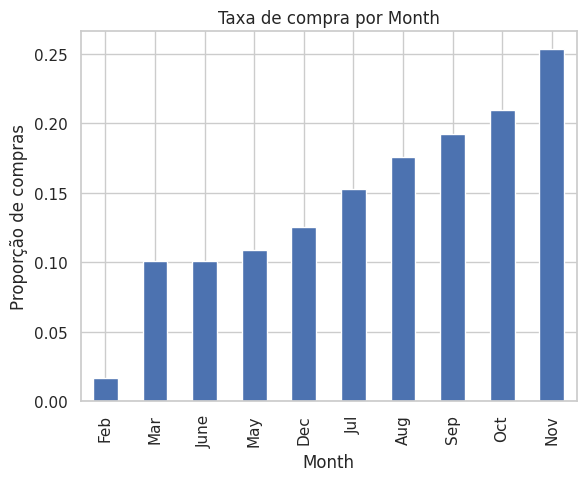

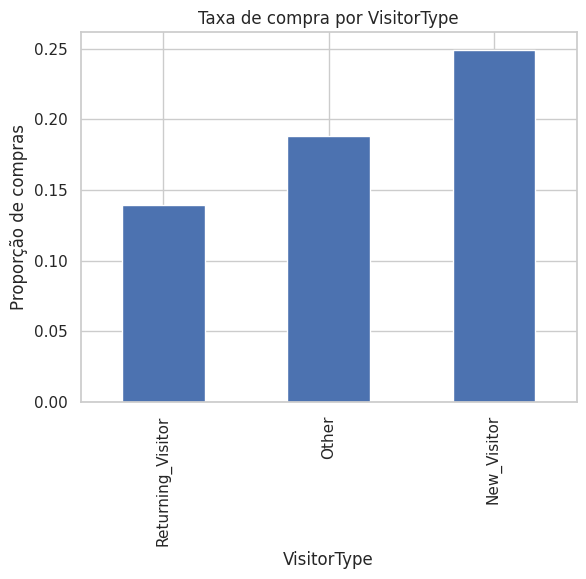

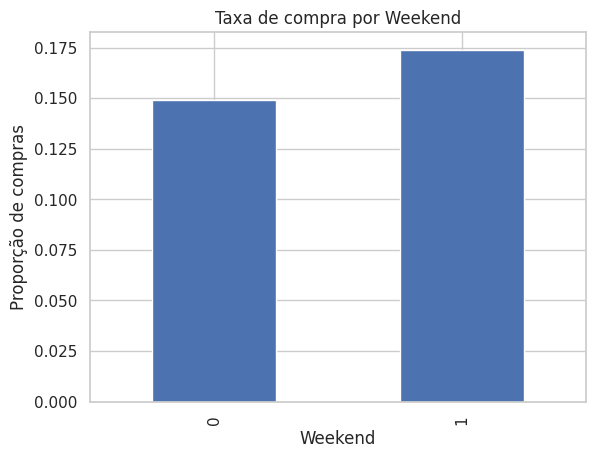

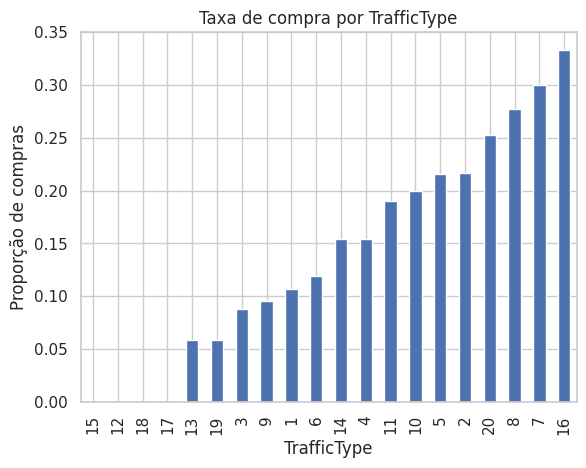

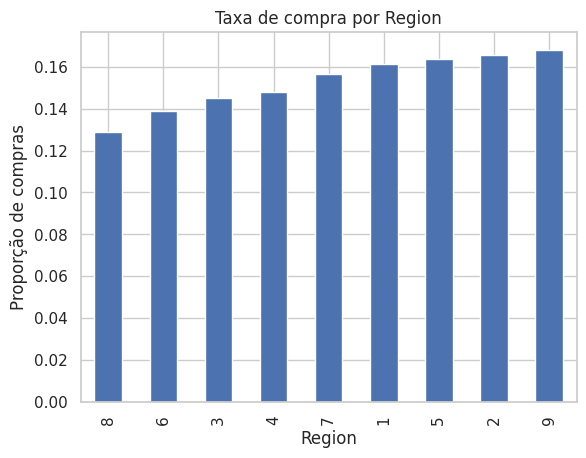

In [ ]:
cat_cols = ["Month", "VisitorType", "Weekend", "TrafficType", "Region"]
for col in cat_cols:
    df.groupby(col)["Revenue"].mean().sort_values().plot(
        kind="bar", title=f"Taxa de compra por {col}")
    plt.ylabel("Proporção de compras"); plt.show()

In [ ]:
cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
for col in cat_cols:
    vc = df[col].value_counts()
    print(f"{col}: {len(vc)} categorias | raras (<1%): {list(vc[vc < len(df)*0.01].index)}")
print("Colunas após one-hot ≈", sum(df[c].nunique() for c in cat_cols) + 10 + 1)

Month: 10 categorias | raras (<1%): []
VisitorType: 3 categorias | raras (<1%): ['Other']
OperatingSystems: 8 categorias | raras (<1%): [8, 6, 7, 5]
Browser: 13 categorias | raras (<1%): [3, 13, 7, 12, 11, 9]
Region: 9 categorias | raras (<1%): []
TrafficType: 20 categorias | raras (<1%): [9, 7, 15, 19, 14, 18, 16, 12, 17]
Colunas após one-hot ≈ 74


In [ ]:
#Assimetria baixa (menor que 1 em módulo): o StandardScaler é suficiente.
#Assimetria alta, com muitos zeros e cauda longa (provável nas durações e em PageValues): uma transformação log1p antes do StandardScaler tende a ajudar bastante o KNN e o SVM.
#Outliers extremos (razão entre máximo e p99 muito alta): considerar o RobustScaler ou o log. Remover outliers é arriscado aqui, porque os compradores costumam estar justamente nas caudas.

num_cols = ["Administrative", "Administrative_Duration", "Informational",
            "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
            "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

resumo = pd.DataFrame({
    "assimetria": df[num_cols].skew(),
    "% zeros": (df[num_cols] == 0).mean() * 100,
    "máximo / p99": df[num_cols].max() / df[num_cols].quantile(0.99),
}).round(2)
resumo

,assimetria,% zeros,máximo / p99
Administrative,1.96,46.78,1.93
Administrative_Duration,5.62,47.88,4.09
Informational,4.04,78.66,4.00
Informational_Duration,7.58,80.49,3.56
ProductRelated,4.34,0.31,3.19
ProductRelated_Duration,7.26,6.12,7.35
BounceRates,2.95,44.75,1.00
ExitRates,2.15,0.62,1.00
PageValues,6.38,77.86,4.23
SpecialDay,3.30,89.85,1.00


In [ ]:
#Verifica redundâncias

corr = df[num_cols].corr().abs()
pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pares[pares > 0.8].sort_values(ascending=False))

BounceRates     ExitRates                  0.913004
ProductRelated  ProductRelated_Duration    0.860927
dtype: float64


In [ ]:
from scipy.stats import mannwhitneyu, chi2_contingency

num_cols = ["Administrative", "Administrative_Duration", "Informational",
            "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
            "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

linhas = []
for c in num_cols:
    a, b = df.loc[df.Revenue == 0, c], df.loc[df.Revenue == 1, c]
    linhas.append({"Atributo": c,
                   "Média sem compra": a.mean(), "Média com compra": b.mean(),
                   "Mediana sem compra": a.median(), "Mediana com compra": b.median(),
                   "p (Mann-Whitney)": mannwhitneyu(a, b).pvalue})
pd.DataFrame(linhas).round(3)

,Atributo,Média sem compra,Média com compra,Mediana sem compra,Mediana com compra,p (Mann-Whitney)
0,Administrative,2.118,3.394,0.000,2.000,0.0
1,Administrative_Duration,73.740,119.483,0.000,52.367,0.0
2,Informational,0.452,0.786,0.000,0.000,0.0
3,Informational_Duration,30.236,57.611,0.000,0.000,0.0
4,ProductRelated,28.715,48.210,16.000,29.000,0.0
5,ProductRelated_Duration,1069.988,1876.210,510.190,1109.906,0.0
6,BounceRates,0.025,0.005,0.004,0.000,0.0
7,ExitRates,0.047,0.020,0.029,0.016,0.0
8,PageValues,1.976,27.265,0.000,16.758,0.0
9,SpecialDay,0.068,0.023,0.000,0.000,0.0


In [ ]:
# Padronizar grafia do mês
df["Month"] = df["Month"].replace({"June": "Jun"})

# Duplicados: decisão do grupo
REMOVER_DUPLICADOS = False   # mude para False se decidirem manter

if REMOVER_DUPLICADOS:
    antes = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Removidas {antes - len(df)} linhas duplicadas → {len(df)} registros")

# Recriar X e y a partir do df limpo
X = df.drop(columns="Revenue")
y = df["Revenue"]
print(X.shape, y.value_counts(normalize=True).round(3).to_dict())

(12330, 17) {0: 0.845, 1: 0.155}


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Proporção de compras – treino:", round(y_train.mean(), 3),
      "| teste:", round(y_test.mean(), 3))

Treino: (9864, 17) | Teste: (2466, 17)
Proporção de compras – treino: 0.155 | teste: 0.155


In [ ]:
log_cols = ["Administrative", "Administrative_Duration", "Informational",
            "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
            "PageValues"]
scale_cols = ["BounceRates", "ExitRates", "SpecialDay"]
cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
bin_cols = ["Weekend"]

preprocess = ColumnTransformer([
    ("log", Pipeline([
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scaler", StandardScaler()),
    ]), log_cols),
    ("num", StandardScaler(), scale_cols),
    ("cat", OneHotEncoder(min_frequency=0.01,                  # agrupa categorias < 1%
                          handle_unknown="infrequent_if_exist",
                          sparse_output=False), cat_cols),
    ("bin", "passthrough", bin_cols),
])

# Conferência (só no treino; o ajuste real acontece dentro de cada fold)
Xt = preprocess.fit_transform(X_train)
print("Colunas após o pré-processamento:", Xt.shape[1])

Colunas após o pré-processamento: 58


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # mesma divisão para todos

scoring = {"accuracy": "accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1"}

modelos = {
    "KNN": (KNeighborsClassifier(), {
        "clf__n_neighbors": [5, 11, 21],
        "clf__weights": ["uniform", "distance"],
    }),
    "SVM": (SVC(random_state=SEED), {
        "clf__C": [0.1, 1, 10],
        "clf__class_weight": [None, "balanced"],
    }),
    "MLP": (MLPClassifier(max_iter=500, early_stopping=True, random_state=SEED), {
        "clf__hidden_layer_sizes": [(50,), (100,), (100, 50)],
        "clf__activation": ["relu", "tanh"],
        "clf__alpha": [1e-4, 1e-3],
    }),
}

buscas = {}
for nome, (clf, grade) in modelos.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    gs = GridSearchCV(pipe, grade, cv=cv, scoring=scoring, refit="f1", n_jobs=-1)
    gs.fit(X_train, y_train)
    buscas[nome] = gs
    print(f"{nome}: melhor F1 = {gs.best_score_:.3f} | {gs.best_params_}")

KNN: melhor F1 = 0.628 | {'clf__n_neighbors': 21, 'clf__weights': 'distance'}
SVM: melhor F1 = 0.671 | {'clf__C': 0.1, 'clf__class_weight': 'balanced'}
MLP: melhor F1 = 0.651 | {'clf__activation': 'relu', 'clf__alpha': 0.001, 'clf__hidden_layer_sizes': (100, 50)}


In [ ]:
# Validação cruzada aninhada: o GridSearch (laço interno, 5 folds) roda dentro
# de cada fold externo, então a estimativa não é enviesada pela escolha dos hiperparâmetros
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)

linhas_aninhada = []
for nome, (clf, grade) in modelos.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    gs_interno = GridSearchCV(pipe, grade, cv=cv, scoring="f1", n_jobs=-1)
    res = cross_validate(gs_interno, X_train, y_train, cv=outer_cv, scoring=scoring)
    linhas_aninhada.append({
        "Modelo": nome,
        **{m: f"{res[f'test_{m}'].mean():.3f} ± {res[f'test_{m}'].std():.3f}" for m in scoring},
    })

resultados_aninhada = pd.DataFrame(linhas_aninhada)
resultados_aninhada

,Modelo,accuracy,precision,recall,f1
0,KNN,0.897 ± 0.003,0.712 ± 0.017,0.565 ± 0.028,0.630 ± 0.017
1,SVM,0.875 ± 0.003,0.568 ± 0.010,0.809 ± 0.029,0.667 ± 0.010
2,MLP,0.899 ± 0.001,0.710 ± 0.019,0.587 ± 0.032,0.642 ± 0.013


In [ ]:
linhas = []
for nome, gs in buscas.items():
    res = pd.DataFrame(gs.cv_results_)
    for _, r in res.iterrows():
        linhas.append({
            "Modelo": nome,
            "Configuração": {k.replace("clf__", ""): v for k, v in r["params"].items()},
            **{m: f"{r[f'mean_test_{m}']:.3f} ± {r[f'std_test_{m}']:.3f}" for m in scoring},
        })
resultados_cv = pd.DataFrame(linhas)
resultados_cv

,Modelo,Configuração,accuracy,precision,recall,f1
0,KNN,"{'n_neighbors': 5, 'weights': 'uniform'}",0.890 ± 0.008,0.678 ± 0.037,0.558 ± 0.015,0.612 ± 0.023
1,KNN,"{'n_neighbors': 5, 'weights': 'distance'}",0.889 ± 0.007,0.670 ± 0.033,0.555 ± 0.014,0.607 ± 0.021
2,KNN,"{'n_neighbors': 11, 'weights': 'uniform'}",0.893 ± 0.007,0.694 ± 0.037,0.557 ± 0.024,0.617 ± 0.022
3,KNN,"{'n_neighbors': 11, 'weights': 'distance'}",0.893 ± 0.007,0.691 ± 0.038,0.560 ± 0.023,0.618 ± 0.022
4,KNN,"{'n_neighbors': 21, 'weights': 'uniform'}",0.897 ± 0.005,0.716 ± 0.026,0.558 ± 0.020,0.627 ± 0.016
5,KNN,"{'n_neighbors': 21, 'weights': 'distance'}",0.897 ± 0.005,0.713 ± 0.028,0.562 ± 0.020,0.628 ± 0.017
6,SVM,"{'C': 0.1, 'class_weight': None}",0.898 ± 0.006,0.726 ± 0.039,0.548 ± 0.024,0.624 ± 0.020
7,SVM,"{'C': 0.1, 'class_weight': 'balanced'}",0.877 ± 0.009,0.573 ± 0.024,0.810 ± 0.009,0.671 ± 0.018
8,SVM,"{'C': 1, 'class_weight': None}",0.903 ± 0.005,0.732 ± 0.033,0.590 ± 0.021,0.652 ± 0.014
9,SVM,"{'C': 1, 'class_weight': 'balanced'}",0.867 ± 0.008,0.546 ± 0.019,0.828 ± 0.010,0.658 ± 0.012


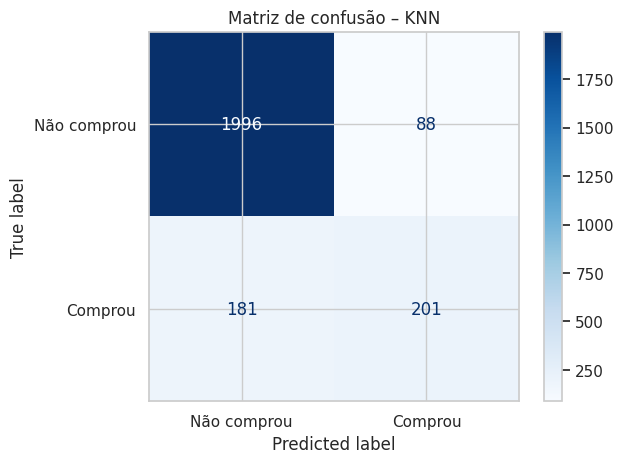

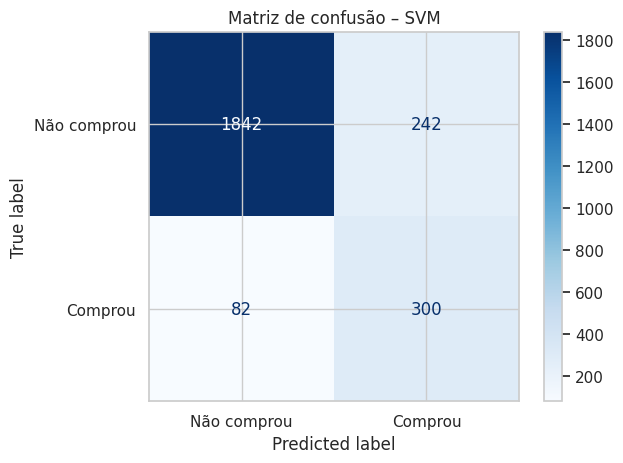

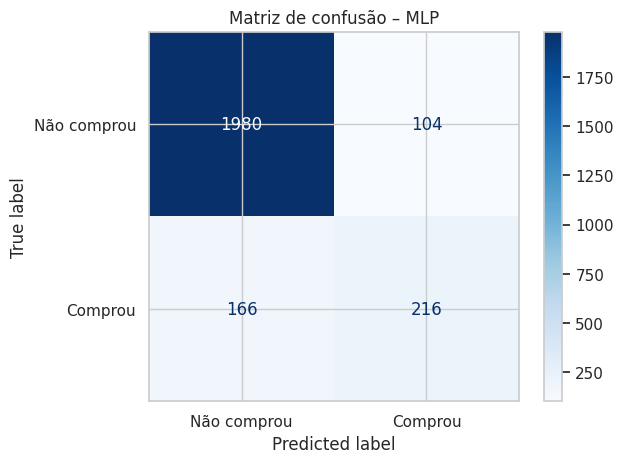

,Modelo,Accuracy,Precision,Recall,F1
0,KNN,0.891,0.696,0.526,0.599
1,SVM,0.869,0.554,0.785,0.649
2,MLP,0.891,0.675,0.565,0.615


In [ ]:
linhas_teste = []
for nome, gs in buscas.items():
    y_pred = gs.best_estimator_.predict(X_test)   # pipeline retreinado no treino inteiro
    linhas_teste.append({
        "Modelo": nome,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
    })
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["Não comprou", "Comprou"], cmap="Blues")
    plt.title(f"Matriz de confusão – {nome}")
    plt.show()

resultados_teste = pd.DataFrame(linhas_teste).round(3)
resultados_teste

KNN → VN, FP, FN, VP = [1996   88  181  201]
SVM → VN, FP, FN, VP = [1842  242   82  300]
MLP → VN, FP, FN, VP = [1980  104  166  216]


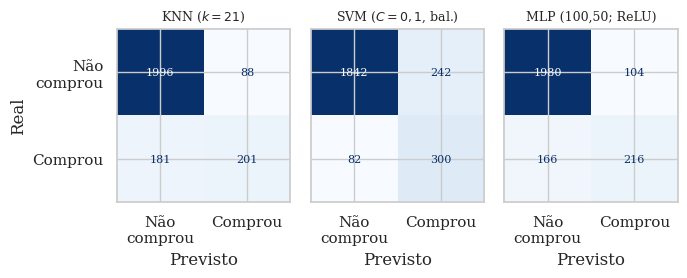

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
from sklearn.metrics import confusion_matrix

os.makedirs("figs", exist_ok=True)

# Fontes compatíveis com o texto do artigo (IEEEtran usa Times)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 8,
    "axes.titlesize": 9,
    "pdf.fonttype": 42,   # embute fontes TrueType (evita problemas no Overleaf)
})

nomes_titulo = {"KNN": "KNN ($k=21$)", "SVM": "SVM ($C=0,1$, bal.)", "MLP": "MLP (100,50; ReLU)"}
rotulos = ["Não\ncomprou", "Comprou"]

# Largura de uma coluna do IEEEtran: ~3,5 pol.
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.5), sharey=True)

for ax, (nome, gs) in zip(axes, buscas.items()):
    y_pred = gs.best_estimator_.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    print(nome, "→ VN, FP, FN, VP =", cm.ravel())   # conferir com o texto

    ConfusionMatrixDisplay(cm, display_labels=rotulos).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(nomes_titulo[nome])
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real" if ax is axes[0] else "")

fig.tight_layout()
fig.savefig("figs/matrizes.pdf", bbox_inches="tight")            # vetorial, para o LaTeX
fig.savefig("figs/matrizes.png", dpi=300, bbox_inches="tight")   # cópia em 300 dpi
plt.show()

# Baixar os arquivos (só funciona no Colab)
from google.colab import files
files.download("figs/matrizes.pdf")
files.download("figs/matrizes.png")